**This part is for doing EDA in order to find the most relevant data and which algo we can put in place**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns

print(os.getcwd())
df = pd.read_csv(r'data\regularite-mensuelle-tgv-aqst.csv', sep=';')
df.describe()


c:\Users\xis\Documents\dossier ecole\cours\IADATA700\dossier_org\projet_sncf\poc\analyse_aristide


,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,12544.000000,12544.000000,12544.000000,0.0,12544.000000,12544.000000,12544.000000,0.0,12544.000000,12544.000000,...,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000
mean,170.628508,272.623884,8.407685,NaN,86.219866,12.499854,3.175135,NaN,38.243304,35.471909,...,27.576531,36.739460,13.025989,5.370615,21.897002,21.491158,20.118126,18.993447,7.762730,7.581653
std,87.730733,183.559230,22.089205,NaN,88.428503,11.660090,5.054562,NaN,31.826539,15.605191,...,23.316212,19.388035,12.684545,6.250032,16.068989,14.914196,14.709970,13.564449,8.682545,9.451102
min,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,-229.269444,NaN,0.000000,-40.109259,...,0.000000,-4.000000,-44.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,99.000000,151.000000,0.000000,NaN,22.000000,6.346596,1.226076,NaN,16.000000,25.958062,...,11.000000,28.732917,4.000000,1.000000,10.714286,11.538462,10.000000,10.000000,0.000000,0.000000
50%,163.000000,230.000000,2.000000,NaN,52.000000,10.560933,2.368000,NaN,30.000000,33.777423,...,22.000000,38.004578,10.000000,3.000000,19.642857,20.000000,18.461538,17.142857,5.882353,5.031800
75%,223.000000,362.000000,7.000000,NaN,126.000000,16.101225,4.031985,NaN,52.000000,42.776681,...,37.000000,47.501389,18.000000,7.000000,30.252101,29.268293,28.571429,25.617573,11.398558,11.111111
max,786.000000,1100.000000,297.000000,NaN,596.000000,316.188095,115.047390,NaN,376.000000,299.600000,...,312.000000,299.600000,202.000000,77.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


In [5]:
df.head()

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


maintenant j'aimerais visualiser le classement des villes par retard de train

In [6]:
stat_gare_depart = df.groupby('Gare de départ').agg(
    total_annule=('Nombre de trains annulés', 'sum'),
    total_retard_depart=('Nombre de trains en retard au départ', 'sum')
)

<Axes: xlabel='total_annule', ylabel='Gare de départ'>

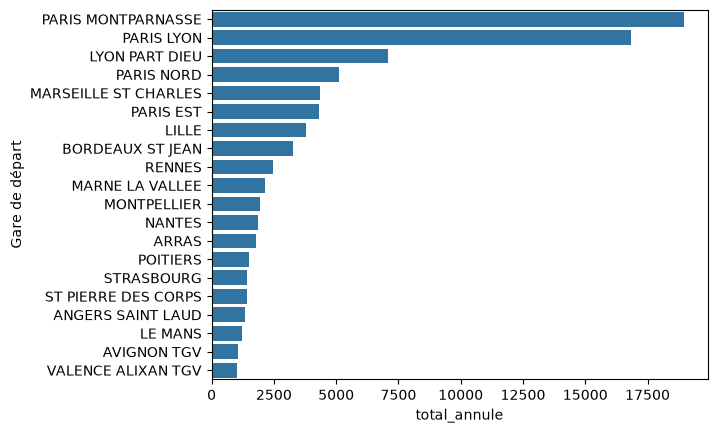

In [7]:
top20_annul = stat_gare_depart.nlargest(20, 'total_annule')
display(sns.barplot(y='Gare de départ', x='total_annule', data=top20_annul))

<Axes: xlabel='total_retard_depart', ylabel='Gare de départ'>

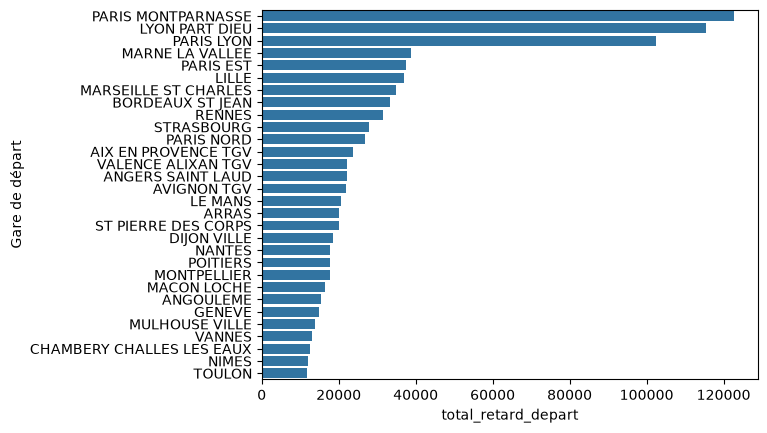

In [8]:
top20_retard = stat_gare_depart.nlargest(30, 'total_retard_depart')
sns.barplot(y='Gare de départ', x='total_retard_depart', data=top20_retard)



je vais ensuite grouper les datas par ville d'arrivé et voir si je trouve des données intéressantes

In [9]:
stat_gare_arrive = df.groupby("Gare d'arrivée").agg(
    total_annule_a = ('Nombre de trains annulés', 'sum'),
    total_retarde_a = ("Nombre de trains en retard à l'arrivée", 'sum')
)
    

<Axes: xlabel='total_annule_a', ylabel="Gare d'arrivée">

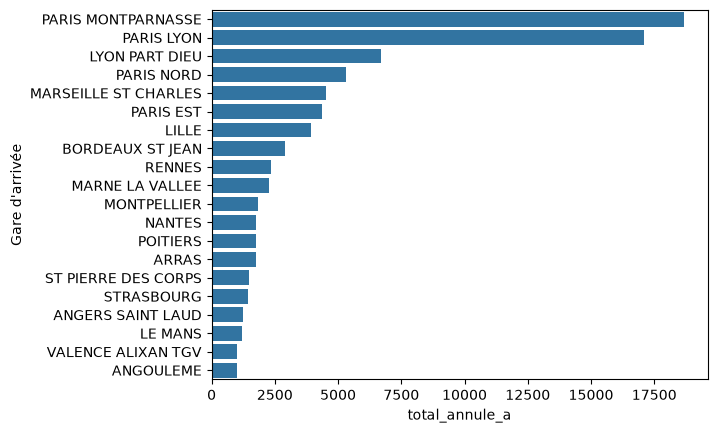

In [10]:
top_20_annul_a = stat_gare_arrive.nlargest(20, "total_annule_a")
sns.barplot(x='total_annule_a', y="Gare d'arrivée", data=top_20_annul_a)

In [11]:
#préparation des données
df['Date'] = pd.to_datetime(df['Date'])
df['annee'] = df['Date'].dt.year
df['mois']  = df['Date'].dt.month
df = pd.get_dummies(df, columns=['Service'])

In [12]:
list_gare =  df['Gare de départ'].unique()
df["gare_arrive_freq"] = df["Gare d'arrivée"].map(df["Gare d'arrivée"].value_counts()+df['Gare de départ'].value_counts())   
df['gare_depart_freq'] = df['Gare de départ'].map(df["Gare d'arrivée"].value_counts()+df['Gare de départ'].value_counts())

In [13]:
df['trajet'] = df['Gare de départ'] + ' → ' + df["Gare d'arrivée"]
print(df['trajet'].nunique())

130


In [14]:
df["ratio_durée_retard"]=df["Retard moyen des trains en retard à l'arrivée"]/df["Durée moyenne du trajet"]

[]

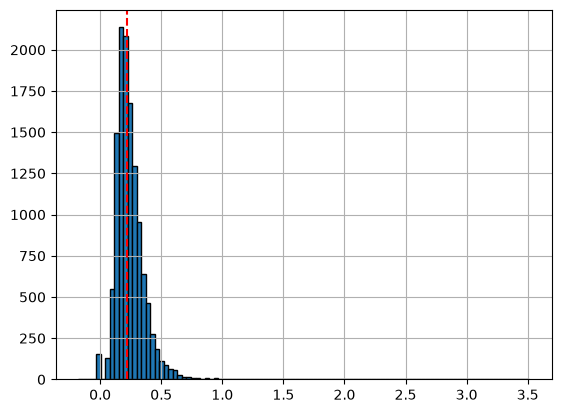

In [15]:
hist = df["ratio_durée_retard"].hist(bins=100, edgecolor='black')
avx = df["ratio_durée_retard"].quantile(0.5)
hist.axvline(avx, color= 'red', linestyle='--')
plt.plot()

<Axes: >

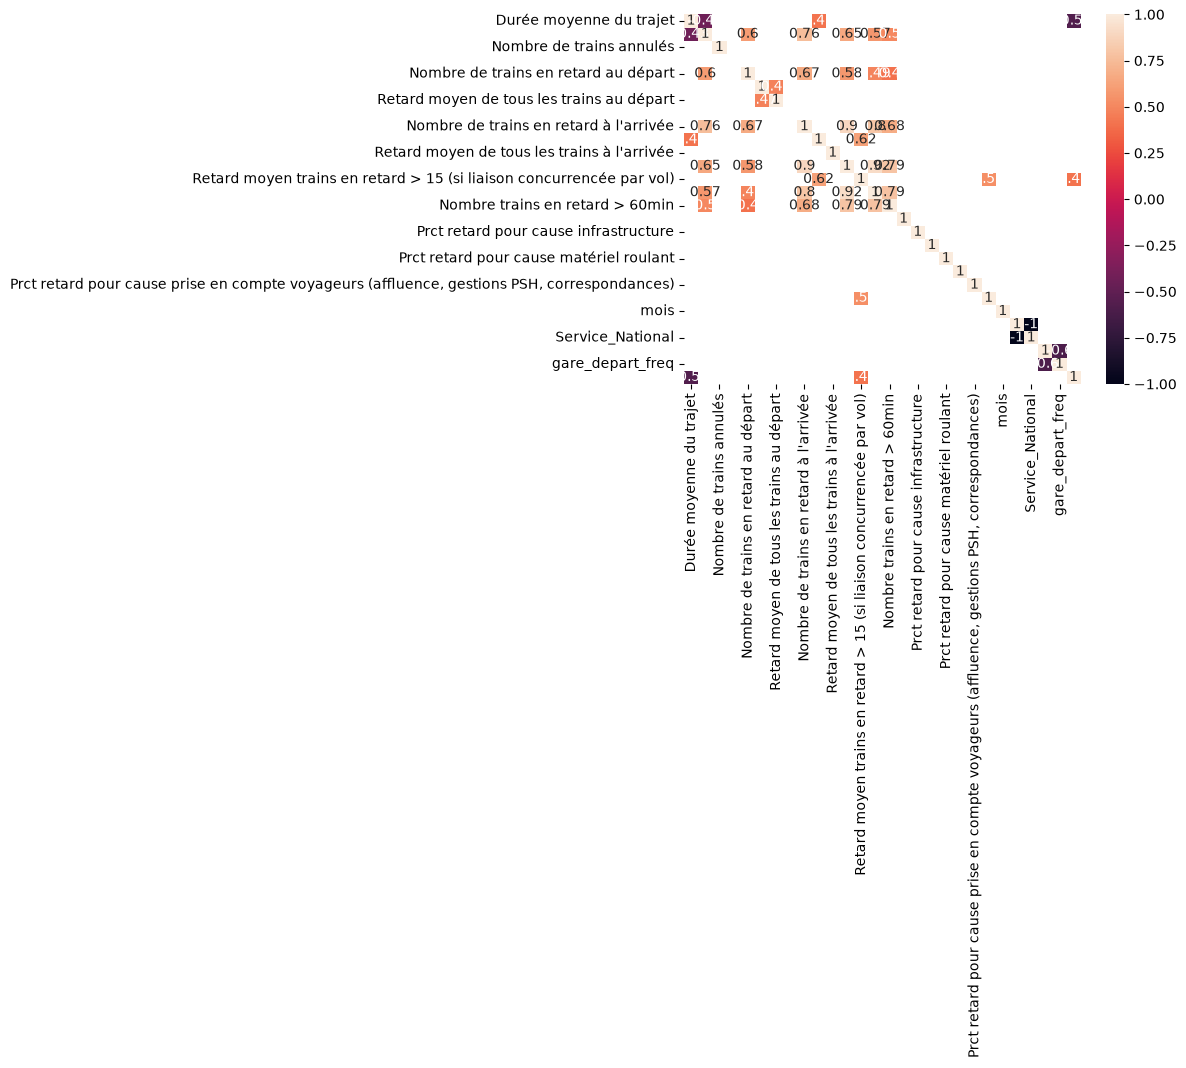

In [35]:
#correlation existante
new_data = df.copy()
#new_data = pd.get_dummies(new_data, columns=["Gare de départ","Gare d\'arrivée"])
corr =  df.corr(numeric_only=True)
sns.heatmap(corr, mask=(corr.abs()<0.4), annot=True)

C:\Users\xis\AppData\Local\Temp\ipykernel_19784\376424346.py:2: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.15)  # espace à gauche pour le label
C:\Users\xis\AppData\Local\Temp\ipykernel_19784\376424346.py:9: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


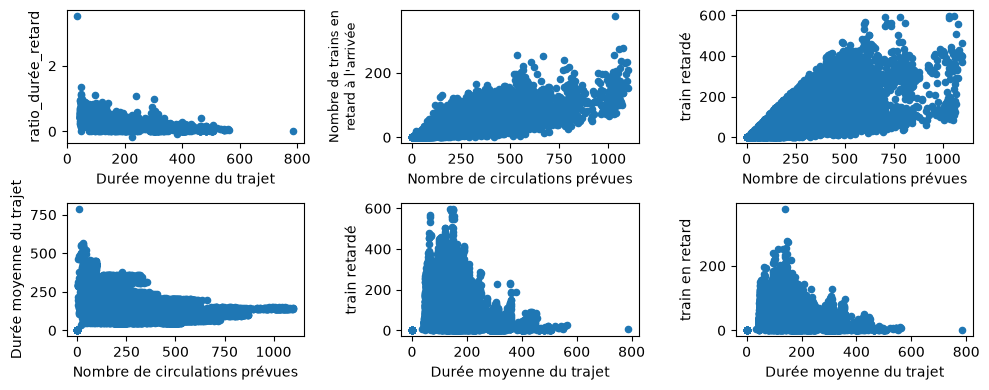

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(10, 4), constrained_layout=True)
fig.subplots_adjust(left=0.15)  # espace à gauche pour le label
df.plot(kind='scatter', x='Durée moyenne du trajet', y='ratio_durée_retard',ax=axes[0,0])
df.plot(kind='scatter', x='Nombre de circulations prévues', y="Nombre de trains en retard à l'arrivée",ax=axes[0,1]).set_ylabel("Nombre de trains en\nretard à l'arrivée", fontsize=9)
df.plot(kind='scatter', x='Nombre de circulations prévues', y="Nombre de trains en retard au départ",ax=axes[0,2]).set_ylabel("train retardé")
df.plot(kind='scatter', x='Nombre de circulations prévues', y="Durée moyenne du trajet",ax=axes[1,0])
df.plot(kind='scatter', y="Nombre de trains en retard au départ", x="Durée moyenne du trajet",ax=axes[1,1]).set_ylabel("train retardé")
df.plot(kind='scatter', y="Nombre de trains en retard à l'arrivée", x="Durée moyenne du trajet",ax=axes[1,2]).set_ylabel("train en retard")
plt.tight_layout()
plt.show()


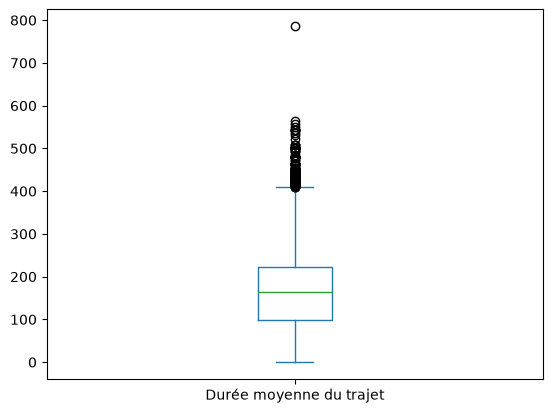

In [18]:
df["Durée moyenne du trajet"].plot.box()
plt.show()

In [19]:
new_data = new_data.rename(columns={'Gare de départ': 'gare_depart', "Gare d'arrivée": 'gare_arrive',"Nombre de trains en retard au départ":"nb_retard_depart","Nombre de trains en retard à l'arrivée":"nb_retard_arrive"})   

In [20]:

def plot_trajet(df, gare_depart, gare_arrive,
                col_retard_dep='nb_retard_depart',
                col_retard_arr='nb_retard_arrive'):
    """Plot l'évolution du retard par mois pour un trajet donné."""
    d = df[(df['gare_depart'] == gare_depart) & (df['gare_arrive'] == gare_arrive)].copy()

    fig, axes = plt.subplots(4, 3, figsize=(14, 16))
    fig.suptitle(f'{gare_depart} -> {gare_arrive}', fontsize=14)

    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee').agg({
            col_retard_dep: 'sum',
            col_retard_arr: 'sum'
        }).reset_index()

        ax.plot(sub['annee'], sub[col_retard_dep], marker='o', label='Départ')
        ax.plot(sub['annee'], sub[col_retard_arr], marker='o', label='Arrivée')
        ax.set_title(f'Mois {mois}')
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb retards')
        ax.legend()

    plt.tight_layout()
    plt.show()


def plot_gare_depart(df, gare,
                     col_retard_dep='nb_retard_depart',
                     col_retard_arr='nb_retard_arrive'):
    """Plot l'évolution du retard par mois pour une gare de départ."""
    d = df[df['gare_depart'] == gare].copy()

    fig, axes = plt.subplots(4, 3, figsize=(14, 16))
    fig.suptitle(f'Gare de départ : {gare}', fontsize=14)

    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee').agg({
            col_retard_dep: 'sum',
            col_retard_arr: 'sum'
        }).reset_index()

        ax.plot(sub['annee'], sub[col_retard_dep], marker='o', label='Départ')
        ax.plot(sub['annee'], sub[col_retard_arr], marker='o', label='Arrivée')
        ax.set_title(f'Mois {mois}')
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb retards')
        ax.legend()

    plt.tight_layout()
    plt.show()


def plot_gare_arrivee(df, gare,
                      col_retard_dep='nb_retard_depart',
                      col_retard_arr='nb_retard_arrive'):
    """Plot l'évolution du retard par mois pour une gare d'arrivée."""
    d = df[df['gare_arrive'] == gare].copy()

    fig, axes = plt.subplots(4, 3, figsize=(14, 16))
    fig.suptitle(f"Gare d'arrivée : {gare}", fontsize=14)

    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee').agg({
            col_retard_dep: 'sum',
            col_retard_arr: 'sum'
        }).reset_index()

        ax.plot(sub['annee'], sub[col_retard_dep], marker='o', label='Départ')
        ax.plot(sub['annee'], sub[col_retard_arr], marker='o', label='Arrivée')
        ax.set_title(f'Mois {mois}')
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb retards')
        ax.legend()

    plt.tight_layout()
    plt.show()   

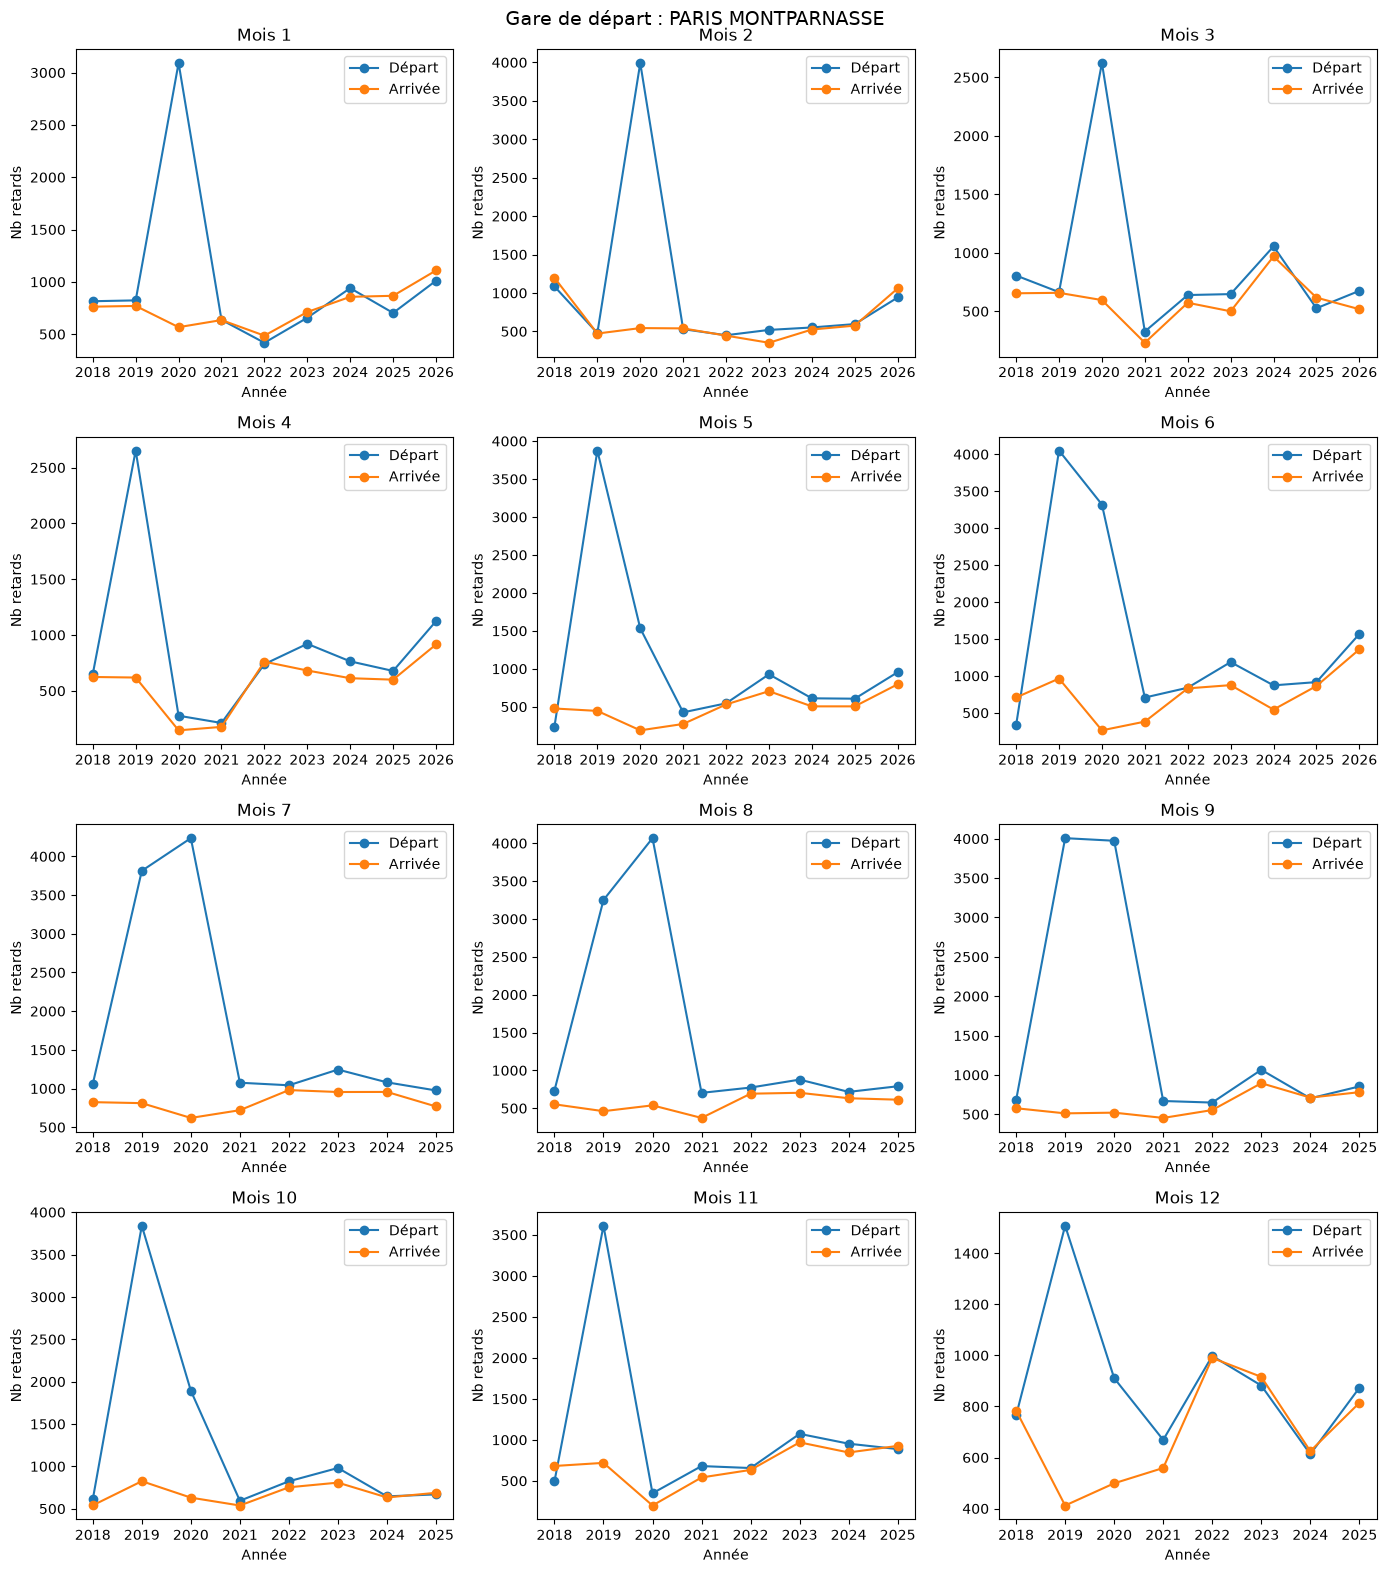

In [21]:
plot_gare_depart(new_data,"PARIS MONTPARNASSE")

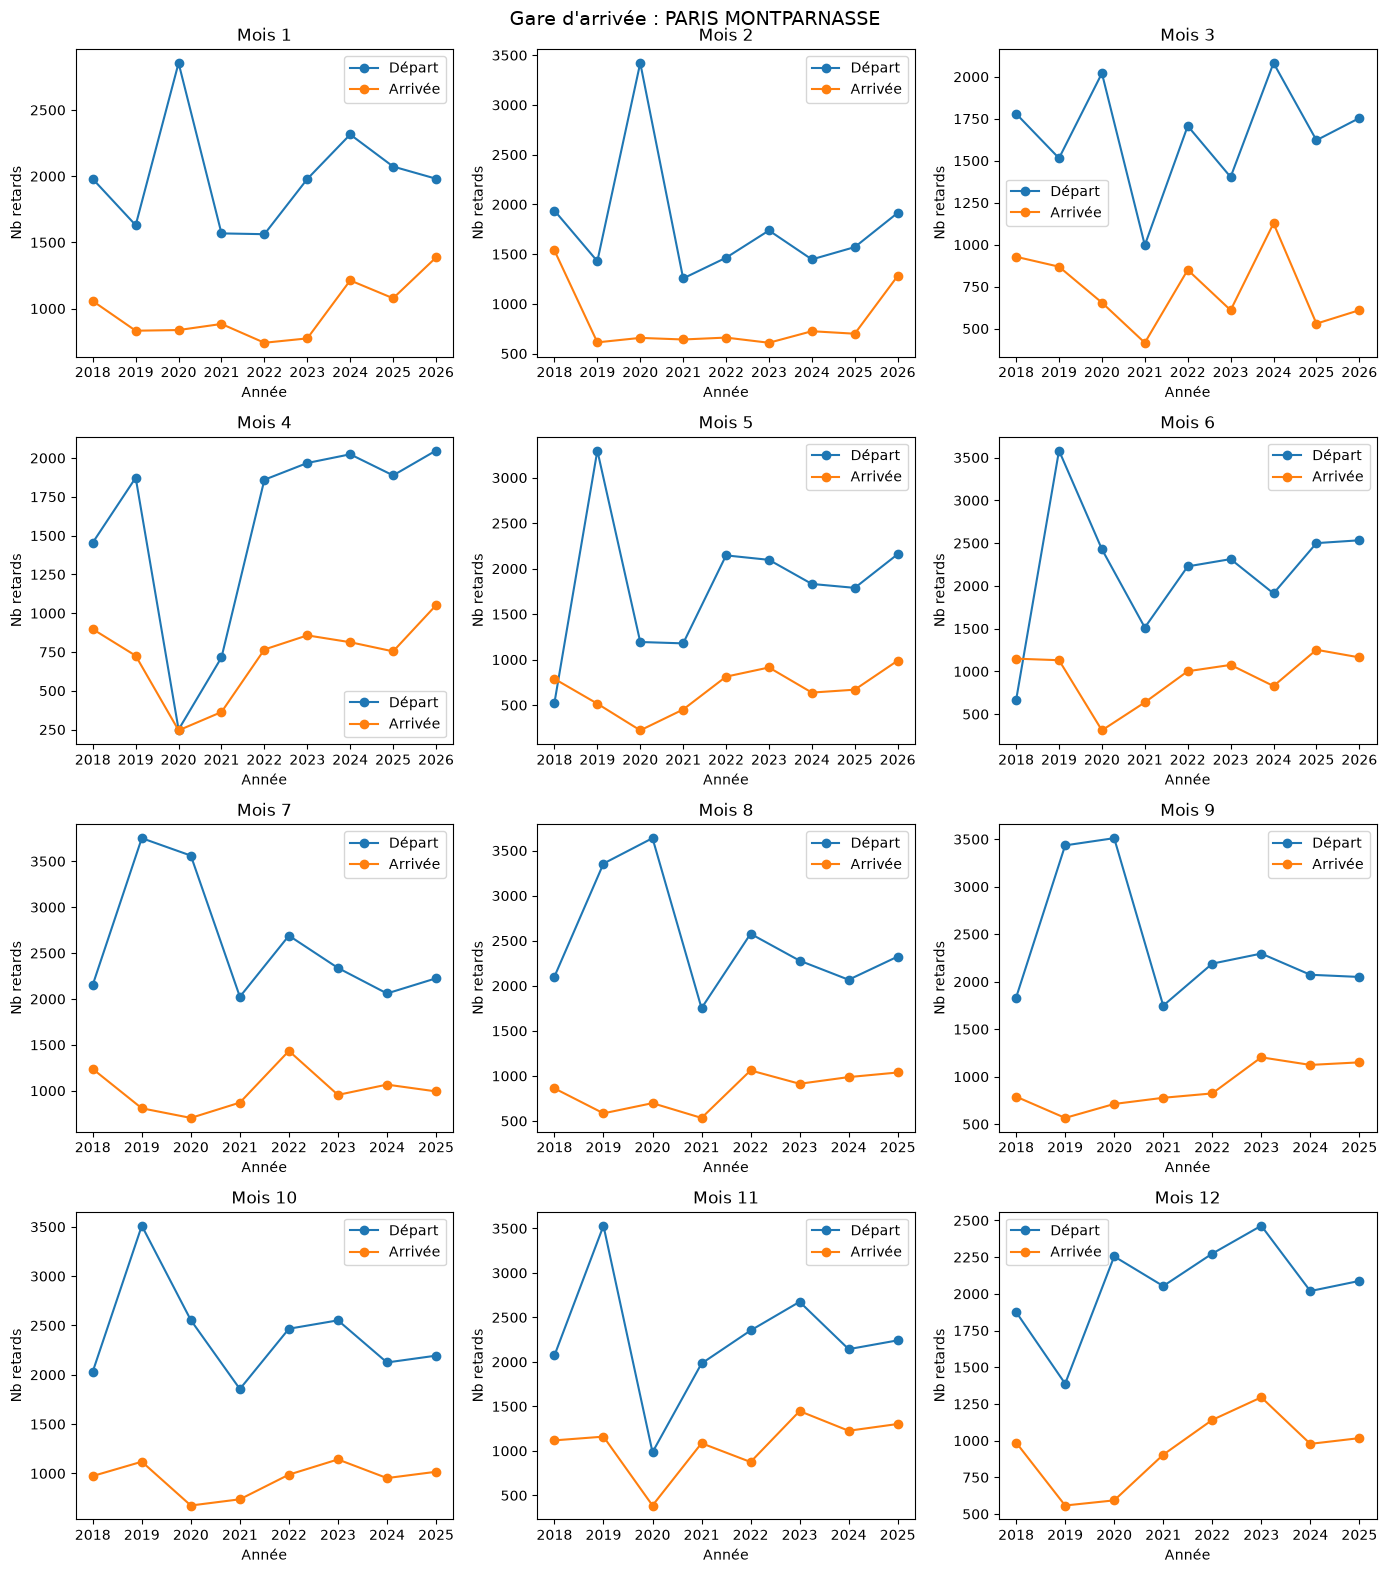

In [22]:
plot_gare_arrivee(new_data, "PARIS MONTPARNASSE")

In [23]:
new_data.head()
# a voir ratio train retard total des trains
stat_retard_trajet = df.groupby('trajet').agg(
    total_retard_depart=('Nombre de trains en retard au départ', 'sum'),
    total_retard_arrive=("Nombre de trains en retard à l'arrivée", 'sum'),
)
stat_retard_trajet.head()

,total_retard_depart,total_retard_arrive
trajet,,
AIX EN PROVENCE TGV → PARIS LYON,23814,4867
ANGERS SAINT LAUD → PARIS MONTPARNASSE,22124,7138
ANGOULEME → PARIS MONTPARNASSE,15452,4430
ANNECY → PARIS LYON,897,2759
ARRAS → PARIS NORD,20193,8730


<Axes: xlabel='total_retard_arrive', ylabel='trajet'>

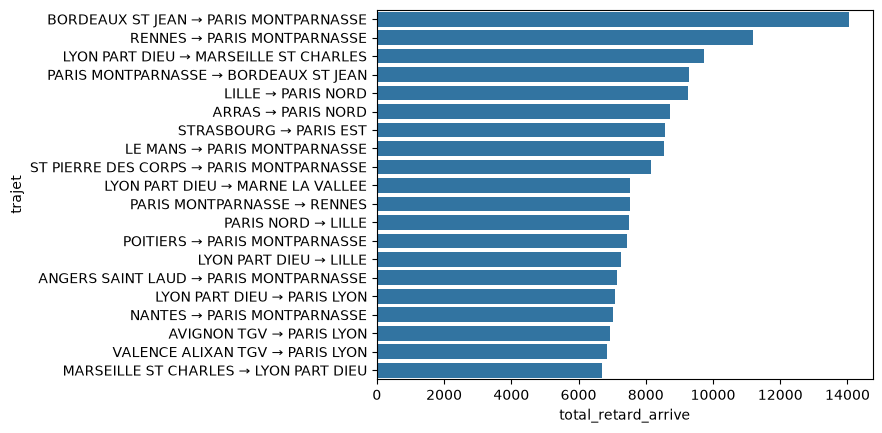

In [24]:
sns.barplot(data=stat_retard_trajet.nlargest(20, "total_retard_arrive"),
            y='trajet', x='total_retard_arrive')

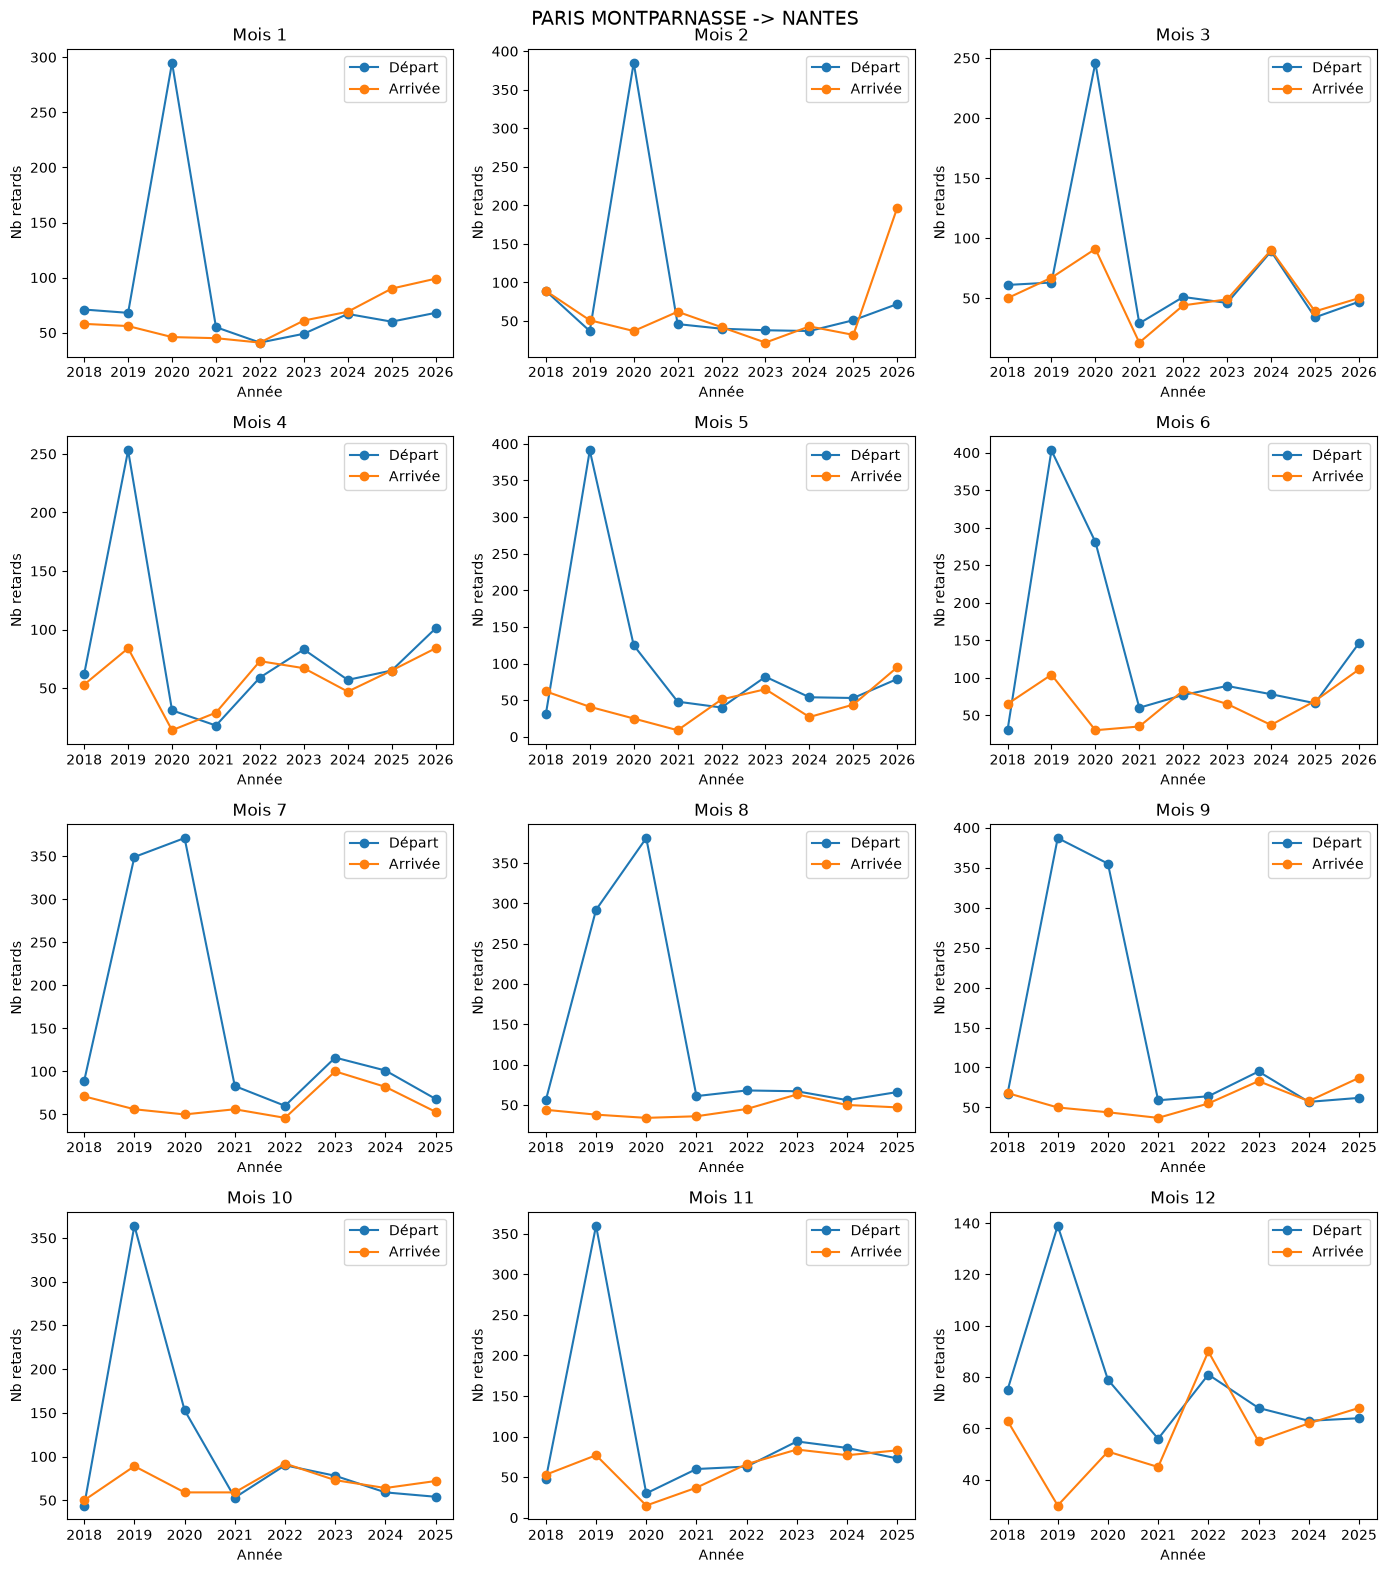

In [25]:
plot_trajet(new_data,"PARIS MONTPARNASSE", "NANTES")

In [26]:
new_data["taux_annulation"]=new_data["Nombre de trains annulés"]/new_data["Nombre de circulations prévues"]

In [31]:
mois_noms = {1: 'Janvier', 2: 'Février', 3: 'Mars', 4: 'Avril',
             5: 'Mai', 6: 'Juin', 7: 'Juillet', 8: 'Août',
             9: 'Septembre', 10: 'Octobre', 11: 'Novembre', 12: 'Décembre'}

def plot_annulation_trajet(df, gare_depart, gare_arrive,
                           col_annulation = "Nombre de trains annulés"):
    d = df[(df['gare_depart'] == gare_depart) & (df['gare_arrive'] == gare_arrive)].copy()
    fig, axes = plt.subplots(4, 3, figsize=(14, 16), constrained_layout=True)
    fig.suptitle(f'{gare_depart} -> {gare_arrive} — Annulations', fontsize=14)
    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee')[[col_annulation]].sum().reset_index()
        ax.plot(sub['annee'], sub[col_annulation], marker='o')
        ax.set_title(mois_noms[mois], fontsize=10)
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb annulations')
        ax.legend()
    plt.show()

def plot_annulation_gare_depart(df, gare, col_dep="Nombre de trains annulés"):
    """plot le nombre de trains annulés pour une gare de départ donnée"""
    d = df[df['gare_depart'] == gare].copy()
    fig, axes = plt.subplots(4, 3, figsize=(14, 16), constrained_layout=True)
    fig.suptitle(f'Gare de départ : {gare} — Trains annulés', fontsize=14)
    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee')[col_dep].sum().reset_index()
        ax.plot(sub['annee'], sub[col_dep], marker='o')
        ax.set_title(mois_noms[mois], fontsize=10)
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb annulations')
    plt.show()   

def plot_annulation_gare_arrivee(df, gare, col_arr="Nombre de trains annulés"):
    """Plot le nombre d'annulation pour une gare d'arrivée donnée"""
    d = df[df['gare_arrive'] == gare].copy()
    fig, axes = plt.subplots(4, 3, figsize=(14, 16), constrained_layout=True)
    fig.suptitle(f"Gare d'arrivée : {gare} — Trains annulés", fontsize=14)
    for mois in range(1, 13):
        ax = axes[(mois - 1) // 3, (mois - 1) % 3]
        sub = d[d['mois'] == mois].groupby('annee')[col_arr].sum().reset_index()
        ax.plot(sub['annee'], sub[col_arr], marker='o')
        ax.set_title(mois_noms[mois], fontsize=10)
        ax.set_xlabel('Année')
        ax.set_ylabel('Nb annulations')
    plt.show()     

C:\Users\xis\AppData\Local\Temp\ipykernel_19784\1242226235.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\xis\AppData\Local\Temp\ipykernel_19784\1242226235.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\xis\AppData\Local\Temp\ipykernel_19784\1242226235.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\xis\AppData\Local\Temp\ipykernel_19784\1242226235.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


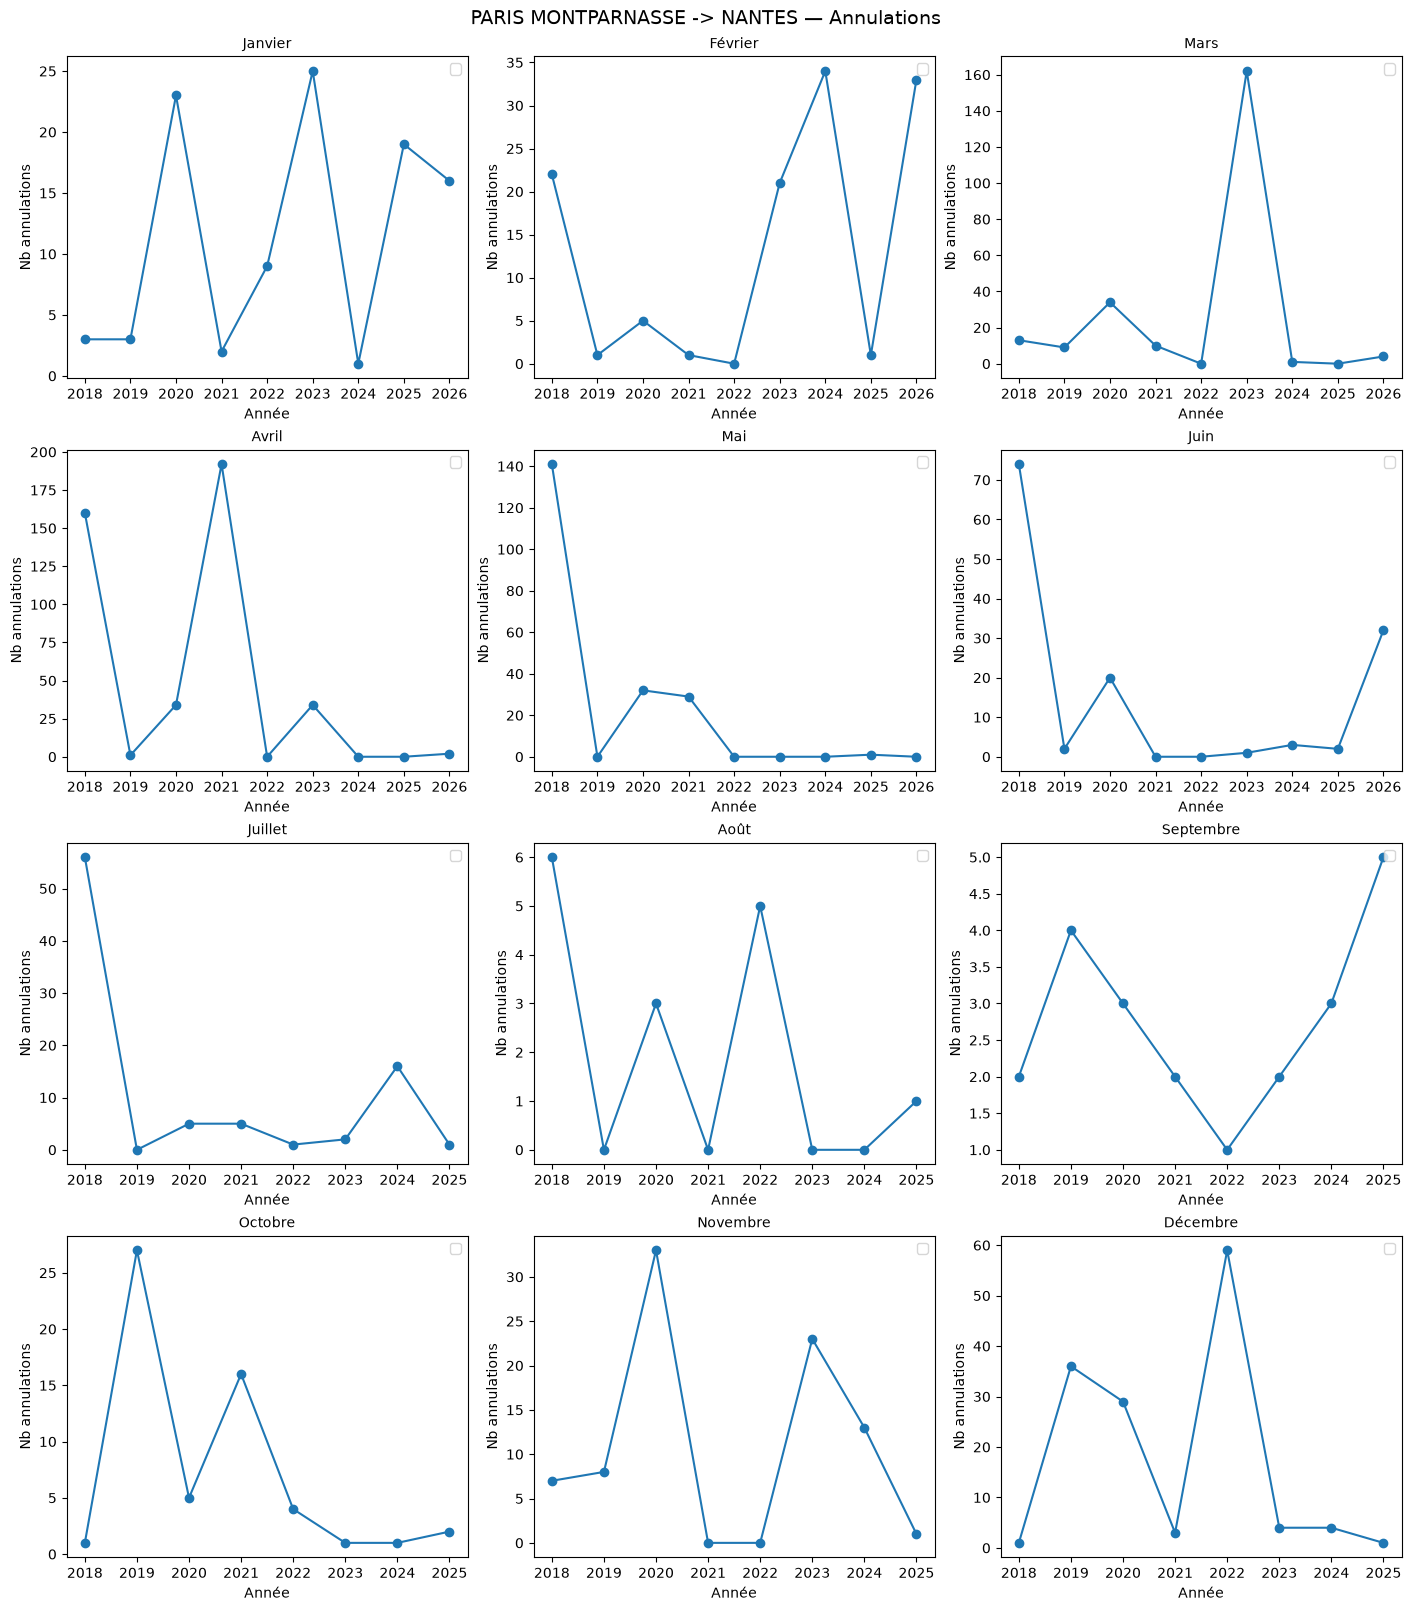

In [32]:
plot_annulation_trajet(new_data,"PARIS MONTPARNASSE", "NANTES")

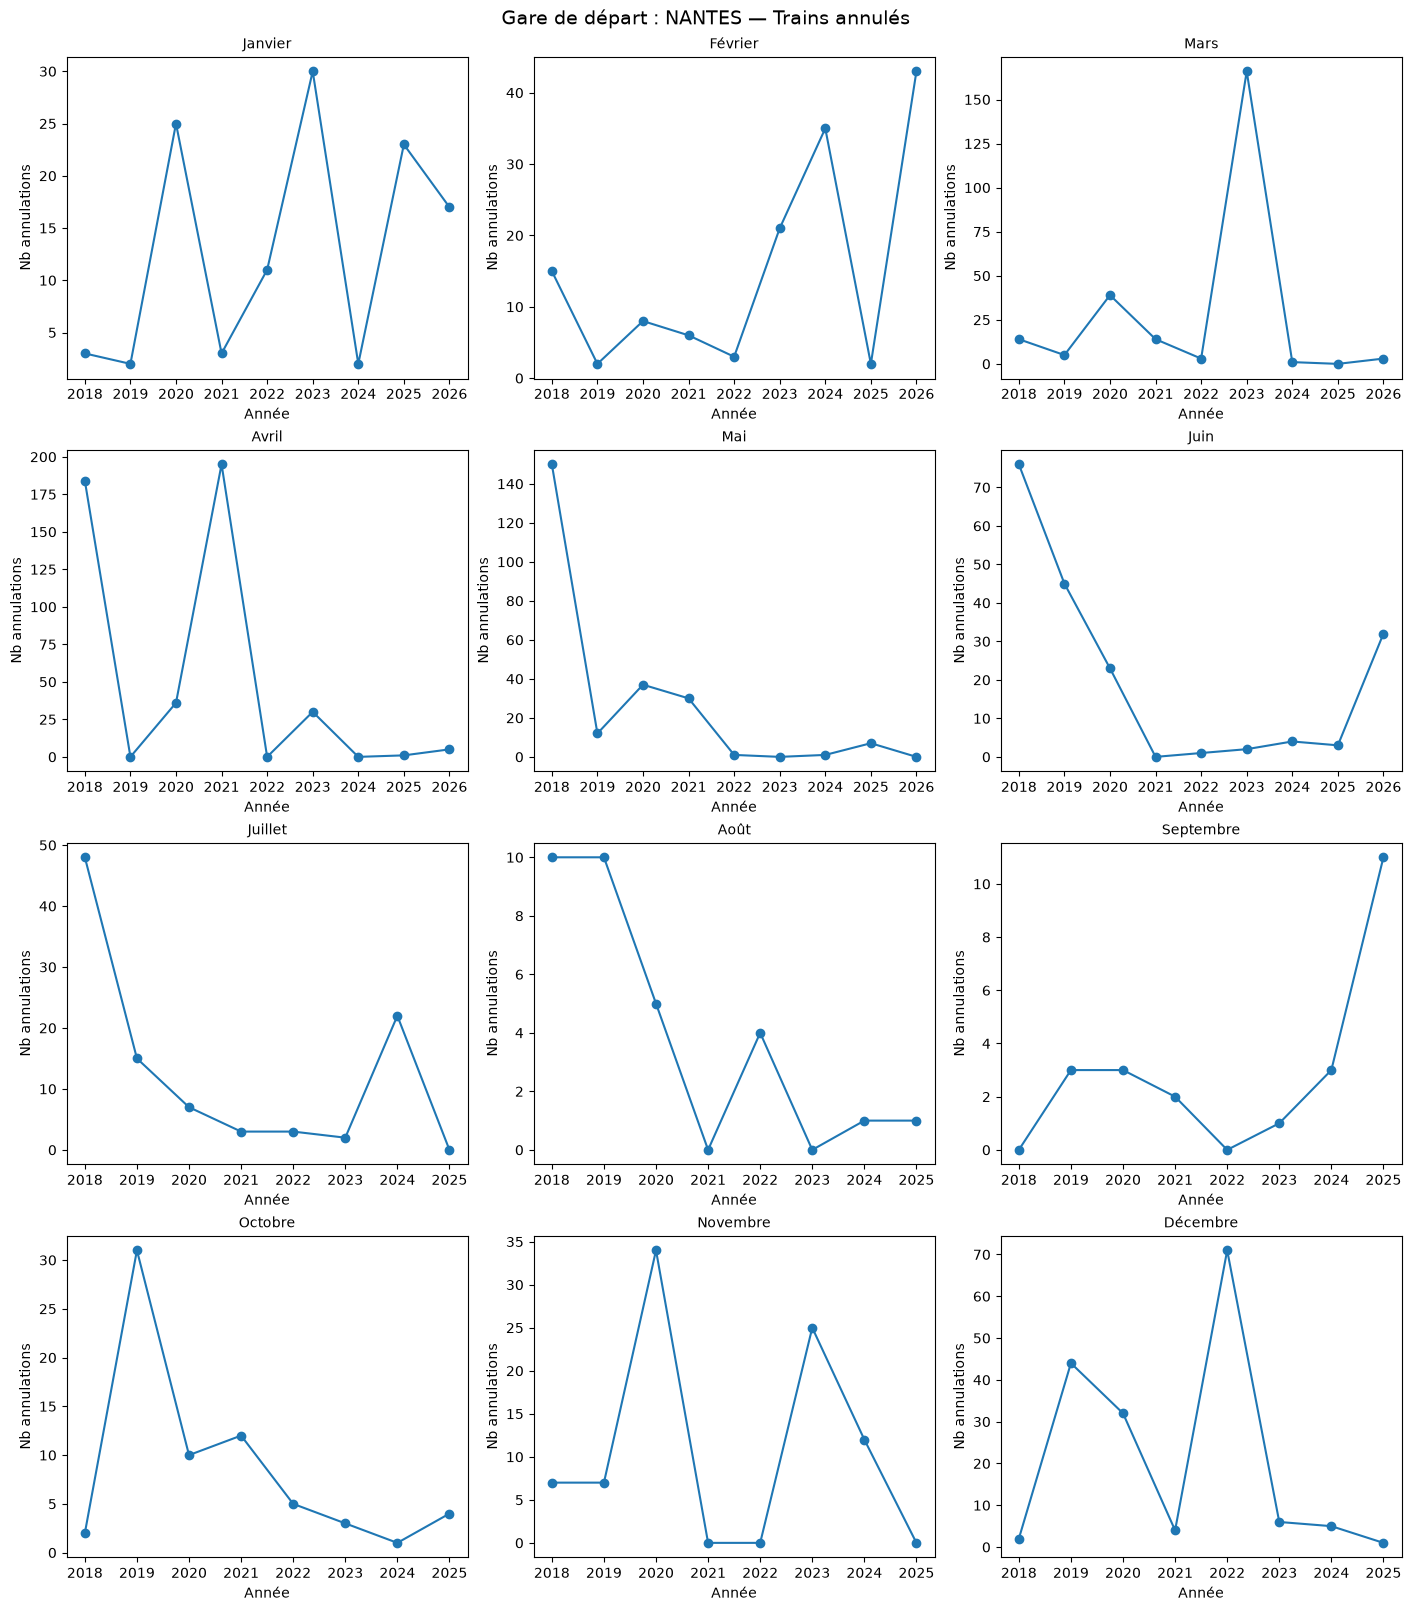

In [33]:
plot_annulation_gare_depart(new_data, "NANTES")

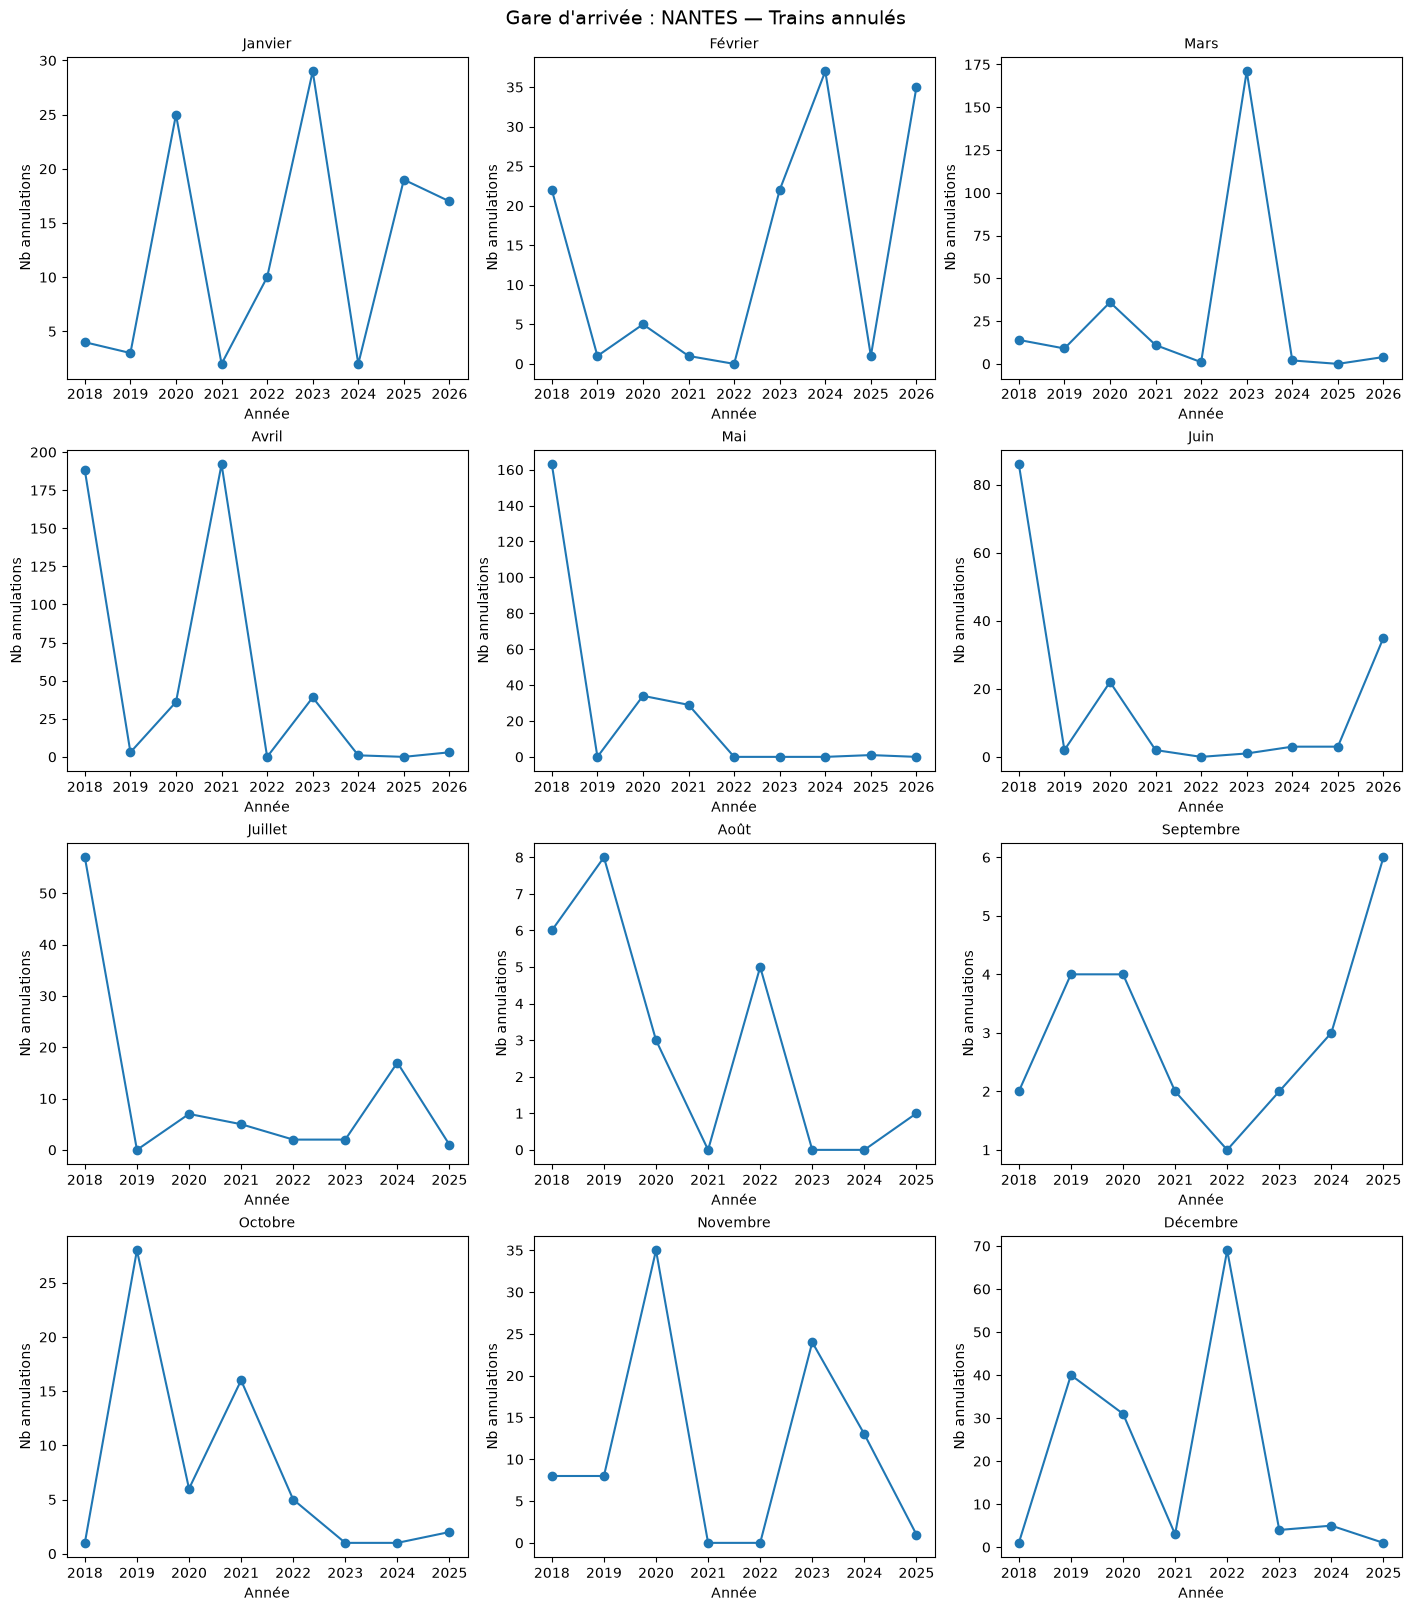

In [34]:
plot_annulation_gare_arrivee(new_data, "NANTES")

## Conclusion

Nous avons essayer de trouver et visualiser des evoluitons de perturbation ou des effets saisonniers. Sur quelques trajets visualisés, il ne semble pas vraiment qu'il y'ait un effet saisonnier, meme si sur certains trajets on a pu visualiser de petites tendance sur des petitess periodes (2-3 ans).

N'ayant pas visualisé tous les effets sur tous les trajets, nous avons décidé de donner la possibilité aux utilisateurs de visualisé les itinéraire désiré.

De plus nous n'avons pas pu trouver d'élements indiquant une possible corrélation entre des features à par celle qui sont déjà logiquement liées (par exemple train en retard au départ et train en retard à l'arrivé).